# Introduction to scikit-learn

Broadly speaking, we can categorize machine learning algorithms into three groups: *supervised learning*, *unsupervised learning*, and *reinforcement learning*.
In the remainder of this course, we'll focus on the first category, and we'll study how we can use the supervised learning algorithms implemented in
[scikit-learn](https://scikit-learn.org/stable/index.html), a popular machine learning library for Python.

Supervised learning uses input data (often called independent variables, features, 
covariates, predictors, or $X$ variables) and the corresponding output data 
(dependent variable, outcome, target, or $y$ variable) to establish some relationship 
$y = f(X)$ within a training dataset. We can then use this relationship to make
predictions about outputs in new data.

Within supervised learning, we distinguish two broad types of approaches:

1. *Regression*, where output data is allowed to take on continuous values; and
2. *Classification*, where output data is restricted to a few values,
  often called categories or labels.

In this lecture, we cover ordinary least squares (OLS), a regression method used in both
econometrics and machine learning. It provides a straightforward introduction to
scikit-learn using a model most students are familiar with.
In the following lectures, we study regularization, which adds a penalty term to the OLS
loss function to improve prediction on new data.

For a more detailed treatment of the topics covered in this and the next lecture, you should check out the book 
[Machine Learning with PyTorch and Scikit-Learn: Develop machine learning and deep learning models with Python](https://github.com/rasbt/machine-learning-book)
and the companion GitHub repository.

***
## Simple linear regression

Imagine the simplest linear model where the dependent variable $y$ is
assumed to be an affine function of the explanatory variable $x$
and an error term $\epsilon$, given by
$$
y_i = \alpha + \beta x_i + \epsilon_i
$$
for each observation $i$.
In econometrics, the parameters $\alpha$ and $\beta$ are called the intercept and
slope parameters, respectively. In machine learning, the terminology
often differs and you might see the same model written as
$$
y_i = b + w x_i + \epsilon_i
$$
where $b$ is called the *bias* and $w$ is called a *weight*. 

Our goal is to estimate the parameters $\alpha$ and $\beta$ which is
most commonly done by ordinary least squares (OLS). OLS is defined as the
estimator that finds the estimates $(\widehat{\alpha}, \widehat{\beta})$
such that the sum of squared errors is minimized. We denote this 
sum of squared errors as the loss function $L$,
$$
L(\alpha, \beta) = \sum_i^N \Bigl(y_i - \alpha - \beta x_i \Bigr)^2
$$
which depends on the choice of parameters $(\alpha, \beta)$. Note that
we use the "hat" notation $\widehat{\alpha}$ to distinguish the OLS
estimate from the (usually unknown) true parameter $\alpha$. The exact
values of $\widehat{\alpha}$ and $\widehat{\beta}$ will vary depending on the sample 
size and estimator used, as we will see later in this unit.

For this simple model, the estimates are given by the expressions
$$
\begin{aligned}
\widehat{\beta} &= \frac{\widehat{Cov}(y,x)}{\widehat{Var}(x)} \\
\widehat{\alpha} &= \overline{y} - \widehat{\beta} \overline{x}
\end{aligned}
$$
where $\widehat{Cov}(\bullet,\bullet)$ and $\widehat{Var}(\bullet)$ are the sample covariance and
variance, respectively, and $\overline{y}$ and $\overline{x}$ are the sample
means of $y$ and $x$. 

There is a straightforward generalization to multiple linear regression,
where we have a vector $\mathbf{x}_i$ of explanatory variables (which usually
includes the intercept) and a parameter vector
$\bm{\beta}$ so that the model is given by
$$
y_i = \mathbf{x}_i'\bm{\beta} + \epsilon_i
$$
If we stack all $\mathbf{x}_i$ in the matrix $\mathbf{X}$ and all $y_i$ in 
the vector $\mathbf{y}$, the OLS estimate 
of $\bm{\beta}$ is given by the well-known formula
$$
\widehat{\bm{\beta}} = \left(\mathbf{X}'\mathbf{X}\right)^{-1} \mathbf{X}'\mathbf{y}
$$

We won't be estimating linear regressions based on this formula and you should
never attempt this, as naively implementing such matrix operations can lead to
numerical problems. Instead, always use pre-packaged least-squares solvers such as
those implemented in NumPy's
[`lstsq()`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)
or SciPy's
[`lstsq()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.lstsq.html)
functions. 
For econometrics and machine learning, it usually makes sense to use linear regression models such as those implemented in 
[statsmodels](https://www.statsmodels.org/stable/regression.html) or
[scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html),
which is what we turn to next.

***
### Simple linear regression with scikit-learn

We start by fitting the simple linear model
$$
y_i = \alpha + \beta x_i + \epsilon_i
$$
using scikit-learn. For now, we proceed using synthetically generated data where we know
the true relationship, assuming that
$$
\begin{aligned}
y_i &= 1 + \frac{1}{2} x_i + \epsilon_i \\
\epsilon_i &\stackrel{\text{iid}}{\sim} N(0, \sigma^2)
\end{aligned}
$$
so that the true parameters are $\alpha = 1$ and $\beta = \frac{1}{2}$. The error term $\epsilon_i$ is assumed to be normally distributed with mean $0$ and variance $\sigma^2$ which we set to $\sigma^2 = 0.7^2$ for this example.

We first define a reusable function that can generate samples of a desired size:

In [1]:
%matplotlib inline

# Imports used in the notebook
import matplotlib.pyplot as plt
import numpy as np

# Default plot fonts
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 10

In [2]:
def create_sample(N, alpha, beta, sigma, rng=None):
    """
    Create sample for simple linear regression

    Parameters
    ----------
    N : int
        Sample size
    alpha : float
        Intercept (or bias)
    beta : float
        Slope (or weight)
    sigma : float
        Standard deviation of the error term
    rng : np.random.Generator, optional
        Random number generator

    Returns
    -------
    x : array
        Predictor variable, uniformly distributed on [0, 10]
    y : array
        Outcome variable
    """
    from numpy.random import default_rng

    # Use a fixed seed when no generator is supplied
    if rng is None:
        rng = default_rng(seed=1234)

    # Use x that are uniformly distributed on [0, 10]
    x = rng.uniform(0, 10, size=N)

    # Normally distributed errors
    epsilon = rng.normal(scale=sigma, size=N)

    # Create outcome variable
    y = alpha + beta * x + epsilon

    return x, y

We then generate a sample of $N=50$ observations as follows:

In [3]:
# Sample size
N = 50

# True model parameters
alpha = 1.0
beta = 0.5
sigma = 0.7

# Create sample
x, y = create_sample(N=N, alpha=alpha, beta=beta, sigma=sigma)

To fit a linear model, we use the 
[`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
class provided by scikit-learn. Before doing so, we need to import it from
[`sklearn.linear_model`](https://scikit-learn.org/stable/api/sklearn.linear_model.html).
Note that most fitting routines in scikit-learn expect a *matrix* as opposed to a vector
even if the model has only one explanatory variable, so we need to insert an artificial
axis to create the matrix `X = x[:, None]`.

In [4]:
from sklearn.linear_model import LinearRegression

# Create LinearRegression object
lr = LinearRegression(fit_intercept=True)

# fit() expects a two-dimensional object, convert x to N-by-1 matrix
X = x[:, None]

# Fit model to data
lr.fit(X, y)

# Predict fitted values
yhat = lr.predict(X)

Linear models in scikit-learn, such as `LinearRegression`, store the fitted slope
coefficients in the `coef_` attribute (which is an array even if there is only a
single explanatory variable). If the model includes an intercept, its fitted value
is stored in the attribute `intercept_`:

In [5]:
# Extract parameter estimates from LinearRegression object
alpha_hat = lr.intercept_
beta_hat = lr.coef_[0]

print(f'Estimated alpha: {alpha_hat:.3f}')
print(f'Estimated beta: {beta_hat:.3f}')

Estimated alpha: 1.376
Estimated beta: 0.482


Note that the attributes `coef_` and `intercept_` do not exist before the `fit()` method has been called, and attempting to access them will raise an `AttributeError`.

The following function visualizes the sample as a scatter plot of $(x_i, y_i)$ and adds the fitted line (in solid orange). Intuitively, for $x=0$ the fitted line has the value $\widehat{\alpha}$ (the intercept) and its slope is equal to $\widehat{\beta}$.

In [6]:
def plot_regression(x, y, alpha, beta, alpha_hat, beta_hat, title=None):
    """
    Plot observations, true and fitted regression lines, and residuals.

    Parameters
    ----------
    x : array
        Explanatory variable
    y : array
        Observed response variable
    alpha : float
        True intercept
    beta : float
        True slope
    alpha_hat : float
        Estimated intercept
    beta_hat : float
        Estimated slope
    title : str, optional
        Title for the plot
    """
    import matplotlib.pyplot as plt

    yhat = alpha_hat + beta_hat * x

    _fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')

    # Plot observations
    ax.scatter(x, y, s=20, c='none', ec='steelblue', alpha=1.0, lw=0.75, label='y')

    # Connect observed and fitted values
    for i in range(len(x)):
        ax.plot([x[i], x[i]], [y[i], yhat[i]], lw=0.5, ls=':', c='black', alpha=0.9)

    # Plot true relationship
    label = r'$y = \alpha + \beta x$'
    ax.axline((0.0, alpha), slope=beta, lw=1.5, ls='--', c='black', label=label)

    # Plot regression line
    label = r'$\widehat{y} = \widehat{\alpha} + \widehat{\beta} x$'
    ax.axline((0.0, alpha_hat), slope=beta_hat, lw=1.5, c='darkorange', label=label)

    # Add annotations
    ax.set_xlabel('Explanatory variable: x')
    ax.set_ylabel(r'Response variable: y, $\widehat{y}$')
    ax.axhline(alpha_hat, lw=0.5, c='black')
    ax.legend(loc='best')
    ax.set_yticks((alpha_hat,), (r'$\widehat{\alpha}$',))
    ax.set_title(title or 'Simple linear regression')

We use this function to visualize the true relationship and the fitted line:

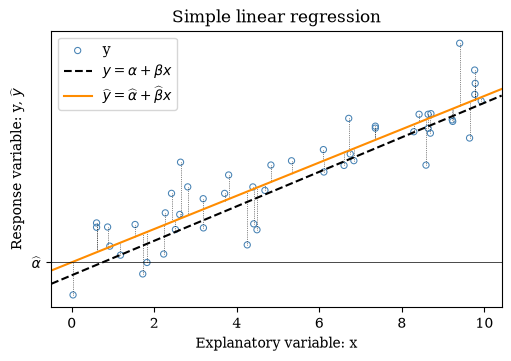

In [7]:
plot_regression(x, y, alpha=alpha, beta=beta, alpha_hat=alpha_hat, beta_hat=beta_hat)

The dashed black line shows the true relationship which is known in this synthetic sample, but in general is unknown for real data. For small sample sizes, the true and estimated parameters need not be close as the graph illustrates. The graph also shows the prediction errors as the dotted lines between the sample points $y_i$ and the fitted model. OLS minimizes the sum of the squares of these distances.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Write a loop to recreate and re-estimate the model for samples of size 10, 50, 100, 1000, and 10000.
2. Print the estimated values of $\alpha$ and $\beta$. Can you say something about the deviation from the true values as the sample size increases?
</div>
<span style="display: none;">YourTurnEnd</span>

***
### Digression: Machine learning versus econometrics

At this point it's instructive to revisit the difference between the machine learning
approach in scikit-learn vs. the traditional econometric approach. To illustrate this, we use
[statsmodels](https://www.statsmodels.org/stable/index.html) to run the regression
$$
y_i = \alpha + \beta x_i + \epsilon_i
$$
using the same data as above:

In [8]:
# Sample size
N = 50

# True model parameters
alpha = 1.0
beta = 0.5
sigma = 0.7

# Create sample
x, y = create_sample(N=N, alpha=alpha, beta=beta, sigma=sigma)

# Refit scikit-learn on the same sample used by statsmodels
_ = lr.fit(x[:, None], y)

To use the statsmodels API, we first import it from `statsmodels.api`. We add a constant column for the intercept and fit the same model as above:

In [9]:
import statsmodels.api as sm

# Add constant for intercept
X_with_const = sm.add_constant(x)

# Fit OLS regression
model = sm.OLS(y, X_with_const)
results = model.fit()

print(results.summary())
print('statsmodels coefficients:', results.params)
print('scikit-learn coefficients:', lr.intercept_, lr.coef_[0])

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.810
Method:                 Least Squares   F-statistic:                     209.7
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           3.86e-19
Time:                        20:52:48   Log-Likelihood:                -54.171
No. Observations:                  50   AIC:                             112.3
Df Residuals:                      48   BIC:                             116.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3762      0.204      6.758      0.0

As you can see from the regression table, the estimated coefficients for $\alpha$
(labeled `const`) and $\beta$ (labeled `x1`) are identical to those computed by
scikit-learn. The difference is that the econometrics package puts more emphasis on
inference, i.e., reporting standard errors (column `std err`), t-statistics (column
`t`), the F-statistic, and other metrics that allow you to test hypotheses, for example
whether any individual coefficient is statistically different from zero. This aspect is
completely missing from scikit-learn because there the focus is on fitting models that
perform well in out-of-sample prediction.

The fitted result stores the coefficients in `results.params`  and standard errors in `results.bse`. Its
`results.conf_int(alpha=0.05)` method returns the lower and upper endpoints of
95% confidence intervals. Row 0 is the intercept; row 1 is the slope.


<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Estimate the statsmodels regression for samples of size 10, 20, 50, 100, 1000,
and 10000.

1. Use `create_sample()` with $\sigma=4.0$ and a fixed seed 1234.
2. For each sample, print the slope's standard error (`results.bse[1]`) and 95% confidence interval (`results.conf_int()[1]`).
3. How do the standard errors change, and which intervals exclude zero?

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Training and test samples

In econometrics, we usually emphasize *inference*, i.e., we are interested in testing a hypothesis about a model parameter, for example, whether it is statistically different from zero. Conversely, in machine learning the emphasis is often on prediction, i.e., our goal is to estimate a relationship from a *training* sample and make predictions for new data. Usually, we use a *test* sample that is different from the training data to assess how well our model is able to predict outcomes for new data which has not been used for estimation.


To demonstrate the use of training and test datasets, we use a simplified variant of the 
Ames house price dataset. The original dataset has 2,930 observations on around 80 features (explanatory variables) which are characteristics of houses sold between 2006 and 2010 in Ames, a city of about 60 thousand inhabitants in the middle of Iowa, USA.
This is one of the most common datasets used in introductory machine learning classes. See
[here](https://jse.amstat.org/v19n3/decock.pdf) for an overview of the data, 
[here](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for detailed documentation of the original variables,
and [here](http://jse.amstat.org/v19n3/decock/AmesHousing.txt) for the original data in tab-separated format.

We use the data from `ames_houses_synthetic.csv` which is stored in the `data/` folder in this repository and contains five variables.
The house characteristics come from the original Ames dataset, while the variable `SalePrice`
contains synthetic prices in thousands of US dollars, predicted using a hedonic
regression model plus an error term. These synthetic prices are suited for teaching
because we can control the data generating process.
Our simplified dataset drops observations with living areas above 300m² and lot areas above 2,500m² since we do not want to deal with a handful of extreme outliers in this lecture.
The goal is to use the variables in the dataset to predict the house price (or "target" in ML terminology).

First, we read in the CSV and inspect the columns contained in the DataFrame:

In [10]:
# Use the local data/ directory
DATA_PATH = '../../data'

# Load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH6-H26/main/data'

In [11]:
import pandas as pd

file = f'{DATA_PATH}/ames_houses_synthetic.csv'
df_ames = pd.read_csv(file)

# List columns present in DataFrame
df_ames.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2881 entries, 0 to 2880
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SalePrice     2881 non-null   float64
 1   LivingArea    2881 non-null   float64
 2   LotArea       2881 non-null   float64
 3   YearBuilt     2881 non-null   int64  
 4   BuildingType  2881 non-null   str    
dtypes: float64(3), int64(1), str(1)
memory usage: 112.7 KB


For our analysis, we extract the target (`SalePrice`) and scale living area:
$$
A_i = LivingArea_i / 100.
$$
In machine learning, it's frequently the case that the features need to be appropriately
scaled to avoid numerical problems (it makes no difference for this simple example,
though). In later lectures, we'll see how scaling can be implemented using functions
provided by scikit-learn.

The coefficient on $A$ measures the price change, in thousands of USD, per
100m² of living area. We retain the original units in the plots.

In [12]:
# Create a new variable A that is the living area in hundreds of square meters
df_ames['A'] = df_ames['LivingArea'] / 100

# Define features and target variable
features = ['A']
target = 'SalePrice'

# Create separate Series / DataFrames for target and features
y = df_ames[target]
X = df_ames[features]

#### Automatically creating training and test samples

Instead of splitting the sample manually into training and test sub-samples, we use
scikit-learn's
[`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
to automate this task. We can specify `test_size` or `train_size` to determine how
much data goes into each sample. If both are omitted, the test sample contains
25% of the data. The `random_state` argument is used to seed the RNG and get
reproducible results:

In [13]:
from sklearn.model_selection import train_test_split

# fraction of data used for test sample
test_size = 0.3

# Split into training / test samples
X_train1, X_test1, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_size,  # Fraction used for test sample
    random_state=1234,  # Seed for random number generator
)

For the plots below, we create two DataFrames that keep the original features
in their original units:

In [14]:
df_train = df_ames.loc[X_train1.index, :]
df_test = df_ames.loc[X_test1.index, :]

We use the training sample to explore which features are related to sale price.
The
[`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
method computes pairwise correlations between numeric variables:

In [15]:
df_train[['SalePrice', 'LivingArea', 'LotArea', 'YearBuilt']].corr()['SalePrice']

SalePrice     1.000000
LivingArea    0.784587
LotArea       0.424788
YearBuilt     0.653875
Name: SalePrice, dtype: float64

Living area (`LivingArea`) has the highest correlation with sale price in the
training sample. We'll start with it, then add construction year and lot area.

### Fitting a linear model to the training sample

Once we have split the sample, we estimate **Model 1**, with an intercept and
living area, on the training sample:
$$
SalePrice_i = \alpha + \beta_A A_i + \epsilon_i.
$$

In [16]:
# Fit model on training sample
model1 = LinearRegression()
model1.fit(X_train1, y_train)

# Extract estimated parameters
intercept = model1.intercept_
slope = model1.coef_[0]

print('Regression coefficients')
print(f'  Intercept: {intercept:.2f}')
print(f'  Slope per 100m²: {slope:.2f}')

Regression coefficients
  Intercept: 9.38
  Slope per 100m²: 122.15


The slope is the predicted price change in thousands of USD for an additional
100m² of living area. Divide it by 100 to obtain the effect per square meter.

The following code creates a scatter plot showing the training and test samples
and adds the fitted line.

In [17]:
def plot_regression_line(X_train, y_train, X_test, y_test, intercept, slope):
    """
    Plot training and test data with fitted regression line.

    Parameters
    ----------
    X_train : array-like
        Training sample living areas in m²
    y_train : Series
        Training sample target variable
    X_test : array-like
        Test sample living areas in m²
    y_test : Series
        Test sample target variable
    intercept : float
        Estimated intercept of the regression model
    slope : float
        Estimated slope of the regression model (per 100m²)
    """
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout='constrained')

    # Plot training data
    axes[0].scatter(X_train, y_train, s=15, c='none', ec='steelblue', alpha=0.8, lw=0.5)

    # Plot test data
    axes[1].scatter(X_test, y_test, s=15, c='none', ec='darkorange', alpha=1.0, lw=0.5)

    # Plot regression line and annotations
    label = r'$\widehat{y} = \widehat{\alpha} + \widehat{\beta} x$'
    titles = ['Training sample', 'Test sample']
    for i, ax in enumerate(axes):
        ax.axline((0.0, intercept), slope=slope / 100, lw=1.5, c='black', label=label)

        # Add annotations
        ax.set_xlabel('Living area in $m^2$')
        ax.set_ylabel(r'Sale price in thousand $')
        ax.set_title(titles[i])
        ax.legend(loc='best')

    fig.suptitle('Fitted simple linear regression', fontweight='bold')

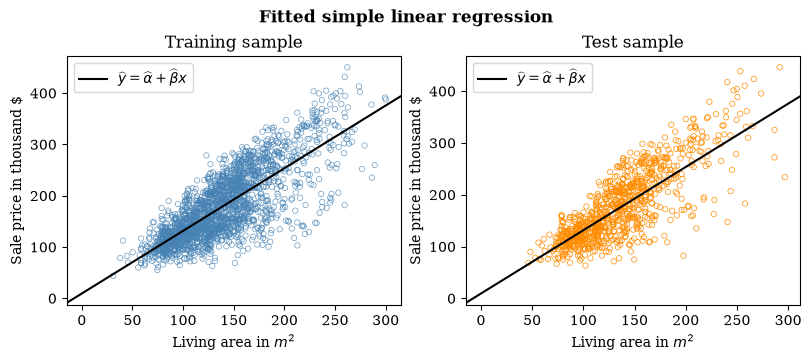

In [18]:
plot_regression_line(
    df_train['LivingArea'], y_train, df_test['LivingArea'], y_test, intercept, slope
)

#### Plotting predictions and errors

We compute prediction errors using the estimated coefficients,
$$
e_i = y_i - \widehat{y}_i = y_i - \widehat{\alpha} - \widehat{\beta}_A A_i.
$$
A positive error means that the model underpredicts the price; a negative error
means that it overpredicts. This process can be simplified by using the `predict()` method of the fitted model which returns $\widehat{y}_i$. The `predict()` method can be used for both the training and test samples.

The following code computes training predictions and errors for the plots:

In [19]:
# Compute training predictions and errors for the plots
yhat_train1 = model1.predict(X_train1)
errors_train1 = y_train - yhat_train1



We use small plotting helpers throughout the lecture:
`plot_errors()` plots the prediction errors against an $x$-variable, and additionally
bins the $x$-variable into eight equal-width intervals and plots the mean error within each bin.
The bin means help us see systematic errors in the conditional mean; the spread
around them describes error variance.

In [20]:
def plot_errors(x, errors, xlabel, title=None, ylabel=None, ax=None, legend=True):
    """
    Plot errors and bin means.

    Parameters
    ----------
    x : array-like
        Variable shown on the x-axis.
    errors : array-like
        Prediction error for each observation.
    xlabel : str
        Label for the x-axis.
    title : str, optional
        Title identifying the model or sample.
    ylabel : str, optional
        Label for the y-axis.
    ax : axes, optional
        Matplotlib axes on which to draw the plot.
    legend : bool, optional
        Whether to show the legend. Default is True.
    """
    # Create a new figure and axes if none are provided
    if ax is None:
        _fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')

    # Plot errors for each observation
    ax.scatter(x, errors, s=15, c='none', ec='steelblue', alpha=0.4, label='Errors')
    # Add horizontal line at y=0 to indicate zero error
    ax.axhline(0, c='black', lw=0.75, ls='--')

    # Convert to arrays so pandas does not align different observation indices.
    df_plot = pd.DataFrame({'x': np.asarray(x), 'error': np.asarray(errors)})
    bins = pd.cut(df_plot['x'], bins=8)
    # Compute means of x and errors within each bin
    df_means = df_plot.groupby(bins, observed=True)[['x', 'error']].mean()
    # Plot means of x and errors within each bin
    xbin, ybin = df_means['x'], df_means['error']
    ax.plot(xbin, ybin, marker='o', c='black', lw=1.5, ms=5, label='Bin means')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel or 'Training error (thousand USD)')
    if title is not None:
        ax.set_title(title, fontweight='bold')
    if legend:
        ax.legend(loc='best')

We first plot Model 1's training errors against living area. The black line shows
mean errors within bins; it does not describe the spread of errors.

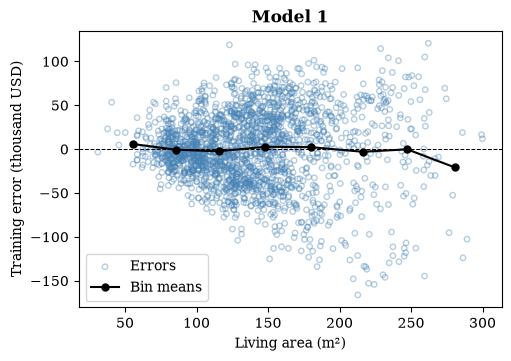

In [21]:
plot_errors(df_train['LivingArea'], errors_train1, 'Living area (m²)', 'Model 1')

Training errors average to zero, but their bin means can still show patterns.
Look at the bin means separately from the spread: a wider spread alone doesn't
mean that the model is missing a pattern in average prices.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Recreate Model 1's training error plot, but put the predicted price
`yhat_train1` on the x-axis instead of living area. Explain why the plot looks
almost identical to the one above.
</div>
<span style="display: none;">YourTurnEnd</span>

***
### Evaluating the model fit

So far, we've used training errors to spot patterns the model misses. To check
predictions on new houses, we compute the following metrics on the test sample.
These become particularly relevant for models with hyperparameters, i.e., settings
chosen outside coefficient estimation, such as polynomial degree or penalty strength.
In later lectures, we'll use these metrics on separate validation data to choose
hyperparameters.

One of the commonly used metrics to evaluate models is the *mean squared error (MSE)*, defined as 
$$
MSE = \frac{1}{N} \sum_{i=1}^N \bigl(y_i - \widehat{y}_i\bigr)^2
$$
which computes the average squared prediction error $y - \widehat{y}$. The magnitude of the MSE is usually hard to interpret, so we often compute the *root mean squared error (RMSE)*,
$$
RMSE = \sqrt{MSE} = \sqrt{\frac{1}{N} \sum_{i=1}^N \bigl(y_i - \widehat{y}_i\bigr)^2}
$$
which can be interpreted in units of the response variable $y$. Lastly, another measure of a model's fit is the
*coefficient of determination* or $R^2$, which is a normalized version of the MSE. The $R^2$ is defined as 
$$
R^2 = 1 - \frac{MSE}{\widehat{Var}(y)}
$$
where $\widehat{Var}(y) = N^{-1}\sum_i (y_i-\overline{y})^2$ is the variance
of the response $y$ computed with divisor $N$, matching the MSE convention.
Intuitively, an $R^2$ of 1 means that the model predicts the response for each observation perfectly (which is unlikely),
whereas an $R^2$ of 0 implies that the model possesses no explanatory power relative to a model that includes only the sample mean. 
For an OLS model with a constant, $R^2$ is bounded between 0 and 1 in the sample
on which the model was estimated (the training sample).
On the other hand, it is possible for the $R^2$ to be negative in a test sample if the model performs worse than a model that predicts the sample mean for all observations.

While these measures are easy to implement ourselves, we can just as well use the functions provided in 
[`scikit-learn.metrics`](https://scikit-learn.org/stable/api/sklearn.metrics.html)
to do the work for us: 

-   [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html#sklearn.metrics.mean_squared_error) for the MSE;
-   [`root_mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html) for the RMSE; and
-   [`r2_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html#sklearn.metrics.r2_score) for the $R^2$.

To illustrate, we compute the test MSE for Model 1 using the observed and predicted
prices. Later comparisons use this same test sample.

In [22]:
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error

# Compute test predictions for the performance metrics
yhat_test1 = model1.predict(X_test1)

# Compute Model 1 test MSE
mse = mean_squared_error(y_test, yhat_test1)
print(f'Model 1 test MSE: {mse:.1f} (thousand USD)²')

Model 1 test MSE: 1720.9 (thousand USD)²


<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Compute Model 1's test RMSE with `root_mean_squared_error()` and $R^2$
with `r2_score()`. 

- Interpret both values, including the units of RMSE.
- What benchmark does $R^2=0$ represent in this test sample?

</div>
<span style="display: none;">YourTurnEnd</span>

We'll work through six models chosen to illustrate different features. To see how
each one predicts new prices, we add its test RMSE and $R^2$ to a comparison table.
These scores are for reporting; we won't use them to choose the next model.
Here's the first row for Model 1:

In [23]:
# Keep a comparison table and add one row after fitting each model.

# Compute test performance metrics for Model 1
rmse_test1 = root_mean_squared_error(y_test, yhat_test1)
r2_test1 = r2_score(y_test, yhat_test1)

df_results = pd.DataFrame(
    {'RMSE': [rmse_test1], 'R²': [r2_test1]}, index=pd.Index(['Model 1'], name='Model')
)
df_results

,RMSE,R²
Model,,
Model 1,41.484218,0.644477


***
## Multiple linear regression

### Data with several explanatory variables

Multiple linear regression extends the simple model to multiple
explanatory variables or regressors. To illustrate, we'll use the same Ames houses
and the same split with several explanatory variables.

Model 1's training errors show a pattern against year built: houses from different
construction years have different mean errors. We can see this using the
`plot_errors()` function defined above:

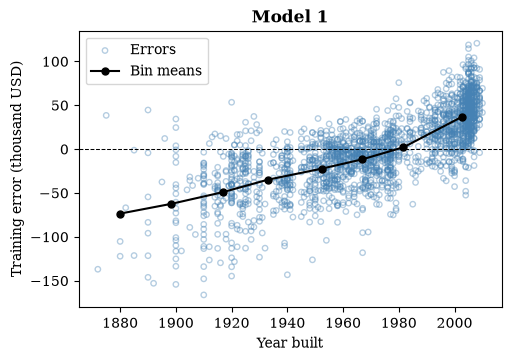

In [24]:
plot_errors(df_train['YearBuilt'], errors_train1, 'Year built', 'Model 1')

#### Adding construction year as an additional regressor

We define **Model 2** as an extension of Model 1 with the construction year as an
additional regressor:
$$
SalePrice_i = \alpha + \beta_A A_i + \beta_T T_i + \epsilon_i,
\qquad T_i = (YearBuilt_i - 1970)/10.
$$
For numerical reasons, we center the construction year around 1970 and scale it by a factor of 10. 
The variable $T$ is now measured in decades since 1970.
Holding living area fixed, $\beta_T$ is the predicted
price difference, in thousands of USD, for a house built a decade later.
The coefficient on $A$ now compares houses with the same construction year.

The column `T` stores the transformed construction year:

In [25]:
# T measures decades since 1970
df_ames['T'] = (df_ames['YearBuilt'] - 1970) / 10

We could again use `train_test_split()` to create a new training and test sample, obtaining the same subsamples as before when using the same seed. Instead, we create two new DataFrames for the training and test samples using the indices of the original training and test samples. In principle, both approaches are equivalent, but this one is guaranteed to use the same training and test samples in case we forget to specify the same seed.

In [26]:
# Define features for Model 2
features2 = ['A', 'T']

# Create new DataFrames for training and test samples with the new features
X_train2 = df_ames.loc[X_train1.index, features2]
X_test2 = df_ames.loc[X_test1.index, features2]

We estimate the model as before, using the same API for simple and multiple linear
regression:

In [27]:
# Fit Model 2 on training sample
model2 = LinearRegression()
model2.fit(X_train2, y_train)

print(f'Model 2 intercept: {model2.intercept_:.2f}')
print('Model 2 coefficients (A, T):', model2.coef_)

Model 2 intercept: 34.59
Model 2 coefficients (A, T): [103.01161897  10.87476896]


The coefficient array `coef_` follows the feature order `['A', 'T']`. The estimated slope on $A$ says that an additional 100m² of living area is associated with a predicted price increase of around 103 thousand USD, holding construction year fixed. On the other hand, the estimated slope on $T$ says that a house built a decade later is associated with a predicted price increase of around 10.8 thousand USD, holding living area fixed. 

Next, we compare training errors against both regressors for Models 1 and 2, i.e., before and after adding the feature $T$.
For this purpose, we define the function `plot_error_comparison()` which allows us to compare training errors against several explanatory variables across several models.

In [28]:
def plot_error_comparison(models, model_names, X_trains, y_train, variables, ylim=None):
    """
    Compare training errors across models and (explanatory) variables.

    Parameters
    ----------
    models : list
        Fitted models or pipelines.
    model_names : list of str
        Titles for the model rows.
    X_trains : list of array-like
        Training feature matrices for the models.
    y_train : array-like
        Observed training prices in thousands of USD.
    variables : dict
        Axis labels mapped to numeric training variables.
    ylim : tuple, optional
        Common vertical error limits; autoscale when omitted.
    """
    xlabels = list(variables)
    xvalues = list(variables.values())
    nrows = len(models)
    ncols = len(xlabels)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4 * ncols, 3 * nrows),
        sharex='col',  # Share x-axis only within columns
        sharey=True,  # Share y-axis across all subplots
        squeeze=False,  # Keep axes two-dimensional even with one row or column
        layout='constrained',
    )

    for i, model in enumerate(models):
        yhat = model.predict(X_trains[i])
        err = np.asarray(y_train) - yhat
        for j in range(ncols):
            ax = axes[i, j]
            plot_errors(
                xvalues[j], err, xlabels[j], model_names[i], ax=ax, legend=False
            )

    if ylim is not None:
        axes[0, 0].set_ylim(ylim)

    return fig, axes

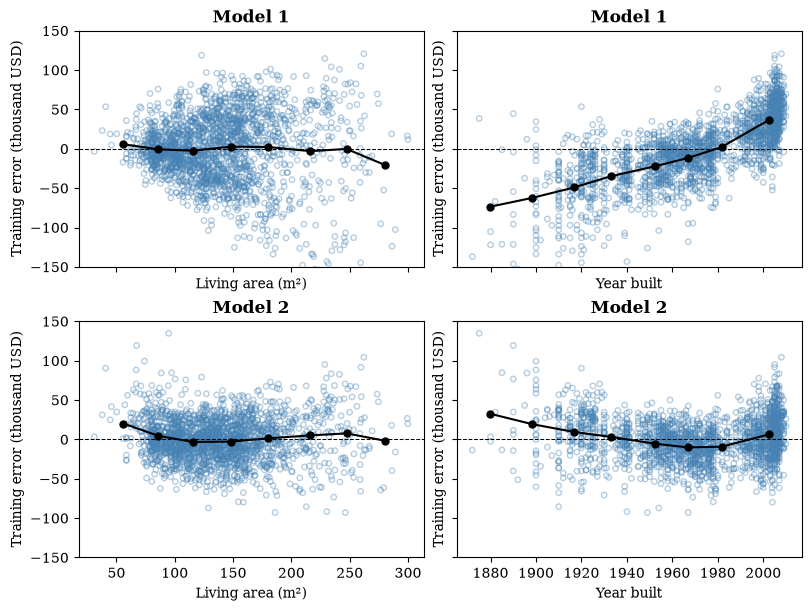

In [29]:
fig, axes = plot_error_comparison(
    [model1, model2],
    ['Model 1', 'Model 2'],
    [X_train1, X_train2],
    y_train,
    variables={
        'Living area (m²)': df_train['LivingArea'],
        'Year built': df_train['YearBuilt'],
    },
    ylim=(-150, 150),
)

As the figure shows, the clearly visible upward pattern of prediction errors
against construction year is no longer present in Model 2.

Finally, we compute the test predictions and evaluate Model 2's performance on the test sample:

In [30]:
# Compute model 2 predictions for test sample
yhat_test2 = model2.predict(X_test2)

# Compute metrics for Model 2
rmse_test2 = root_mean_squared_error(y_test, yhat_test2)
r2_test2 = r2_score(y_test, yhat_test2)

# Add model 2 results to the results DataFrame
df_results.loc['Model 2'] = [rmse_test2, r2_test2]
df_results

,RMSE,R²
Model,,
Model 1,41.484218,0.644477
Model 2,27.896622,0.839230


The table confirms that adding the construction year substantially decreases the test RMSE and increases $R^2$. 

#### Adding lot area as an additional regressor

Next, we plot Model 2's training errors against lot area. The bin means rise over
much of the range, suggesting that lot area could help explain the remaining errors:

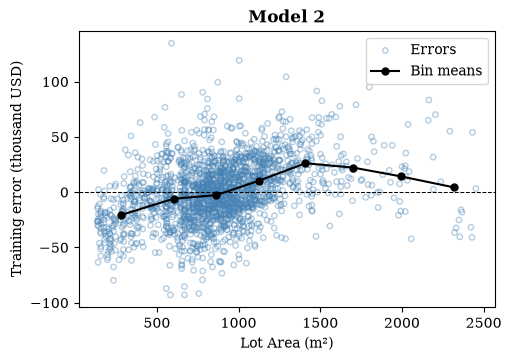

In [31]:
# Compute training errors for the plots
errors_train2 = y_train - model2.predict(X_train2)

plot_errors(df_train['LotArea'], errors_train2, 'Lot Area (m²)', 'Model 2')

We therefore proceed to define **Model 3** which includes lot area as an additional explanatory variable:
$$
SalePrice_i = \alpha + \beta_A A_i + \beta_T T_i + \beta_L L_i + \epsilon_i,
\qquad L_i = LotArea_i / 1000.
$$
For numerical reasons, we scale the lot area by a factor of 1,000. The coefficient on
$L$ is the predicted price change, in thousands of USD, for an additional 1,000m² of
lot area, holding living area and construction year fixed.

Fitting the model on the training data is the same as in the simple case.
We select the additional feature using the indices of `X_train1` and `X_test1`:

In [32]:
# Add (scaled) lot area as an additional regressor
df_ames['L'] = df_ames['LotArea'] / 1000

# Define features for Model 3
features3 = ['A', 'T', 'L']

# Create training and test DataFrames for Model 3
X_train3 = df_ames.loc[X_train1.index, features3]
X_test3 = df_ames.loc[X_test1.index, features3]

# Fit Model 3 on training sample
model3 = LinearRegression()
model3.fit(X_train3, y_train)

print(f'Model 3 intercept: {model3.intercept_:.2f}')
print('Model 3 coefficients (A, T, L):', model3.coef_)

Model 3 intercept: 19.28
Model 3 coefficients (A, T, L): [92.87443441 10.9893512  33.21838988]


The coefficient array `coef_` now stores three values in the same order as the
features in the feature matrix passed when fitting the model. The results say that an
additional 1,000m² of lot area is associated with a predicted price increase of about
33.2 thousand USD, holding living area and construction year fixed.


We compare training errors against lot area before and after adding $L$.
The living-area and year-built panels show how the remaining patterns change
against the other features.

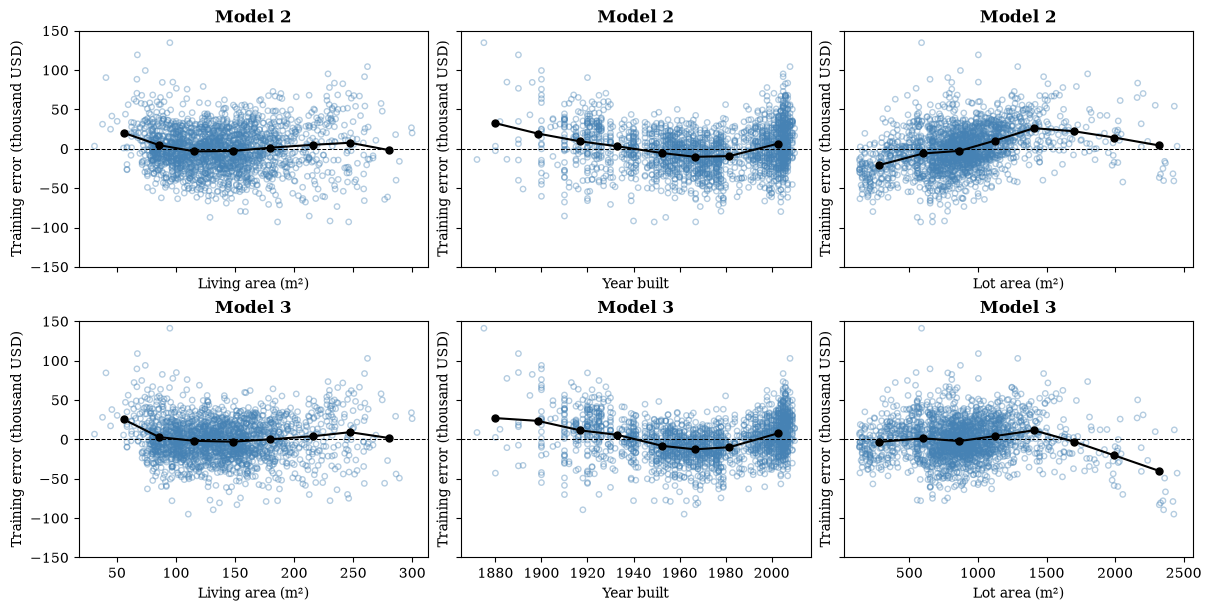

In [33]:
fig, axes = plot_error_comparison(
    [model2, model3],
    ['Model 2', 'Model 3'],
    [X_train2, X_train3],
    y_train,
    variables={
        'Living area (m²)': df_train['LivingArea'],
        'Year built': df_train['YearBuilt'],
        'Lot area (m²)': df_train['LotArea'],
    },
    ylim=(-150, 150),
)

To assess the improvement of Model 3 over the previous two models on the test sample, we compute the RMSE and the $R^2$:

In [34]:
# Compute test predictions for Model 3
yhat_test3 = model3.predict(X_test3)

# Compute test performance metrics for Model 3
rmse_test3 = root_mean_squared_error(y_test, yhat_test3)
r2_test3 = r2_score(y_test, yhat_test3)

# Tabulate test performance metrics for Models 1-3
df_results.loc['Model 3'] = [rmse_test3, r2_test3]
df_results

,RMSE,R²
Model,,
Model 1,41.484218,0.644477
Model 2,27.896622,0.839230
Model 3,25.457015,0.866120


As you see, the addition of lot area as an explanatory variable improves the model fit, even though the improvement is not as large as when we added construction year. 

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Fit a model using living area $A_i$ and lot area $L_i$ as regressors, keeping the same training and test samples.

- Compute its test RMSE and compare it with Models 2 and 3. 
- Use `plot_error_comparison()` to compare its training errors against year built
  with those of Model 3.
- Does lot area compensate for leaving out construction year? Which construction periods does the reduced model tend to overpredict or underpredict?

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Creating polynomial features

Adding construction year and lot area reduces some systematic mean errors,
but these additive models require the effect of each variable to be constant.
Curvature or patterns that differ across construction periods suggest trying
polynomial terms and interactions.

Instead of including additional explanatory variables, we can also create additional terms that are functions of variables. The most common way to do this is to include a polynomial in some feature $x$ (or polynomials in multiple explanatory variables). Thus, a simple model could be turned into a model with several terms such as
$$
y_i = \alpha + \beta_0 x_i + \beta_1 x_i^2 + \beta_2 x_i^3 + \epsilon_i
$$
where $y$ is modeled as a cubic polynomial in $x$. Note that this model is still called *linear* despite the fact that the mapping between $x$ and $y$ is obviously *non-linear*. However, what matters for estimation is that the model is linear in the model parameters $(\alpha, \beta_0, \beta_1, \beta_2)$. Linear models are thus quite flexible since they can include almost arbitrary non-linear transformations of explanatory and response variables.

Applying this approach to the Ames housing data, we extend Model 3 with the interaction between living area $A_i$ and construction
year $T_i$. **Model 4** thus adds $A_i T_i$ as a feature to the regression:
$$
SalePrice_i = \alpha + \beta_A A_i + \beta_T T_i + \beta_L L_i
             + \beta_{AT} A_i T_i + \epsilon_i.
$$
Holding lot area fixed, the area slope is $\beta_A + \beta_{AT} T$ per 100m².
Thus, the price effect of additional living area can differ by construction year.


For now, we create the interaction manually and we'll study in the next section how to automate this process in scikit-learn.

In [35]:
# Interaction term: AT = A times T.
df_ames['AT'] = df_ames['A'] * df_ames['T']

# Features for Model 4: A, T, L, and AT
features4 = ['A', 'T', 'L', 'AT']

# Create training and test DataFrames for Model 4
X_train4 = df_ames.loc[X_train1.index, features4]
X_test4 = df_ames.loc[X_test1.index, features4]

# Fit Model 4 on training sample
model4 = LinearRegression()
model4.fit(X_train4, y_train)
print('Model 4 coefficients (A, T, L, AT):', model4.coef_)

Model 4 coefficients (A, T, L, AT): [93.46883063 -2.49358347 30.96397712  9.32750407]


We can use the estimated coefficients to evaluate the marginal effect of an increase in
living area for houses built at different points in time. For example, for the years
1930, 1970, and 2010, the marginal effects can be computed as follows:

In [36]:
years = np.array([1930, 1970, 2010])
# Compute slopes (marginal effects) for given years using the
# formula: slope = beta_A + beta_AT * (YearBuilt - 1970) / 10
slopes = model4.coef_[0] + model4.coef_[3] * (years - 1970) / 10

df_slopes = pd.DataFrame(
    {'Year built': years, 'Price increase per 100m² (thousand USD)': slopes}
)
df_slopes.round(1)

,Year built,Price increase per 100m² (thousand USD)
0,1930,56.2
1,1970,93.5
2,2010,130.8


The table shows the predicted price increase for an additional 100m² of living
area, holding construction year and lot area fixed. For each construction year,
the slope is constant across living areas. The interaction $A\cdot T$ allows this slope
to differ by construction year. For example, an additional 100m² of living area for a
house built in 2010 is associated with a predicted price increase of 130.8 thousand USD,
while for a house built in 1930 the predicted price increase is only 56.2 thousand USD.

We compute test predictions and evaluate Model 4's RMSE and $R^2$:

In [37]:
# Compute test predictions for Model 4
yhat_test4 = model4.predict(X_test4)

# Compute test performance metrics for Model 4
rmse_test4 = root_mean_squared_error(y_test, yhat_test4)
r2_test4 = r2_score(y_test, yhat_test4)

# Add model 4 results to the results DataFrame
df_results.loc['Model 4'] = [rmse_test4, r2_test4]
df_results

,RMSE,R²
Model,,
Model 1,41.484218,0.644477
Model 2,27.896622,0.839230
Model 3,25.457015,0.866120
Model 4,22.387663,0.896457


The table shows yet another improvement in the model fit compared to Model 3.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Compare the already fitted Models 3 and 4 for houses built before 1950.

- Compute each model's RMSE for these houses in the test sample.
- Use `plot_error_comparison()` to plot both models' errors against living area
  for these houses in the training sample. Does adding the interaction reduce
  the trend in the bin means?

</div>
<span style="display: none;">YourTurnEnd</span>

#### Creating polynomial features automatically

We next extend Model 4 to **Model 5**, a polynomial of degree 2 in $A$, $L$, and $T$
(often the terms "degree" and "order" are used interchangeably, so this might
be called a 2nd-order polynomial). Specifically, if we have two variables $x$
and $z$, such a polynomial would include all terms with exponents summing up to
2 or less:
$$
p(x,z) = \beta_0 + \beta_1 x + \beta_2 z + \beta_3 x^2 + \beta_4 x \cdot z + \beta_5 z^2
$$
We can use these six terms as explanatory variables in our linear models and
estimate the parameters $\beta_0,\dots,\beta_5$. With three input variables, Model 5
contains ten terms: $1,A,L,T,A^2,AL,AT,L^2,LT,T^2$.

It would be quite error-prone to create such polynomials ourselves, so we are going to
use scikit-learn's
[`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
class to accomplish this task. As the name implies, this transformation creates
new features that are polynomials of a given input matrix.
We can request that the resulting data should include an intercept ("bias") by specifying `include_bias=True`. Note that if an intercept is included in the feature matrix, we should fit the linear model *without* an intercept (by specifying `fit_intercept=False`) as otherwise the model would contain two constant terms.

In [38]:
from sklearn.preprocessing import PolynomialFeatures

# Continuous variables used to build polynomial features
CONT_VARIABLES = ['A', 'L', 'T']

# Create training and test DataFrames for Model 5
df_train5 = df_ames.loc[X_train1.index, CONT_VARIABLES]
df_test5 = df_ames.loc[X_test1.index, CONT_VARIABLES]

# Create polynomials of degree 2 or less, including one intercept (bias).
poly = PolynomialFeatures(degree=2, include_bias=True)

# Create 10 features for Model 5: 1, A, L, T, A², AL, AT, L², LT, T²
X_train5 = poly.fit_transform(df_train5)

The `powers_` attribute stores the list of exponents for each generated feature:

In [39]:
# print polynomial exponents
poly.powers_

array([[0, 0, 0],
       [1, 0, 0],
       [0, 1, 0],
       [0, 0, 1],
       [2, 0, 0],
       [1, 1, 0],
       [1, 0, 1],
       [0, 2, 0],
       [0, 1, 1],
       [0, 0, 2]])

The first feature is constructed as
$\mathbf{X}_{(1)}^0 \cdot \mathbf{X}_{(2)}^0 \cdot \mathbf{X}_{(3)}^0$:
the first row of exponents is `[0, 0, 0]`, so this is the intercept.
The second row, `[1, 0, 0]`, gives the first input column $A$.
Here $\mathbf{X}_{(i)}$ refers to the $i$-th column of the input matrix.

Now that we have transformed the input matrix, we can estimate the linear model
on the expanded feature matrix as before, with `fit_intercept=False` so that
there is exactly one constant term:

In [40]:
# Fit linear regression to polynomial features.
model5 = LinearRegression(fit_intercept=False)
model5.fit(X_train5, y_train)

# Tabulate fitted coefficients in a DataFrame
labels = poly.get_feature_names_out(CONT_VARIABLES)
pd.DataFrame({'Coef': model5.coef_}, index=labels)

,Coef
1,48.846243
A,52.342747
L,11.942999
T,-0.761637
A^2,-4.626760
A L,46.300756
A T,8.040642
L^2,-20.181195
L T,2.658046
T^2,1.178710


The fitted model has ten coefficients, including the constant feature.
The `LinearRegression` object's `intercept_` is zero because it did not add
a separate intercept.

We compare Models 4 and 5 against living area, year built, and lot
area, using the same training houses and error limits. Look for changes in the
black bin means, especially against year built and lot area:

In [41]:
# Compute training errors for the plots
errors_train5 = y_train - model5.predict(X_train5)

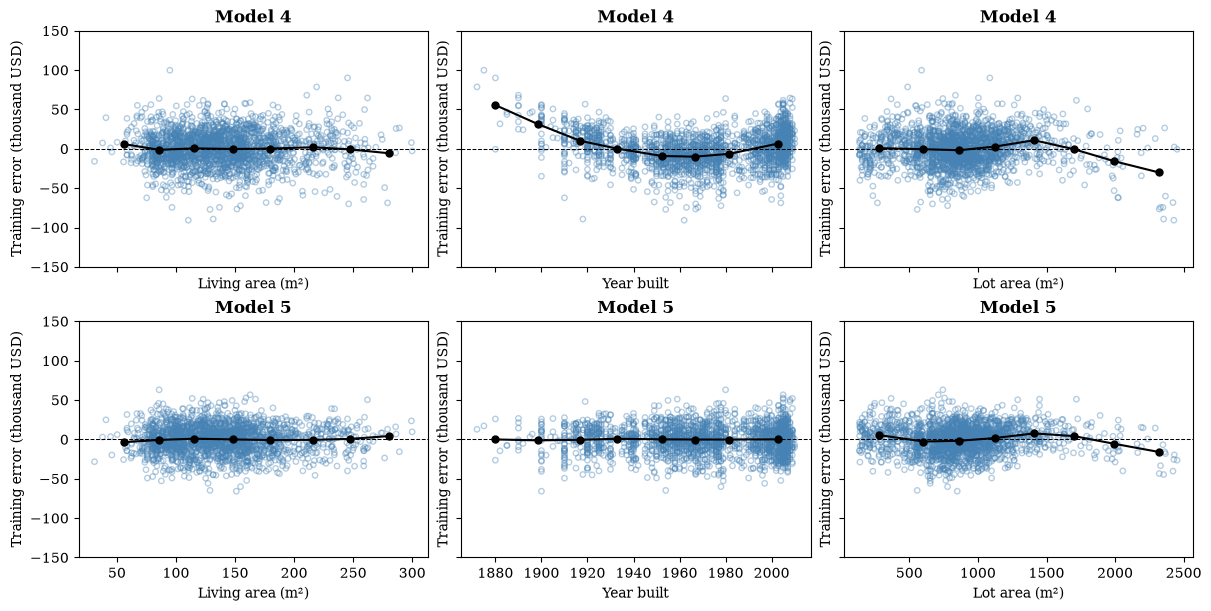

In [42]:
fig, axes = plot_error_comparison(
    [model4, model5],
    ['Model 4', 'Model 5'],
    [X_train4, X_train5],
    y_train,
    variables={
        'Living area (m²)': df_train['LivingArea'],
        'Year built': df_train['YearBuilt'],
        'Lot area (m²)': df_train['LotArea'],
    },
    ylim=(-150, 150),
)

Before computing test predictions, we apply the same fitted polynomial
transformation to the test features using the
[`transform()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html#sklearn.preprocessing.PolynomialFeatures.transform)
method of the `poly` object stored from earlier:

In [43]:
# Apply polynomial transformation to test sample
X_test5 = poly.transform(df_test5)

# Compute predicted values for Model 5
yhat_test5 = model5.predict(X_test5)

# Compute test performance metrics for Model 5
rmse_test5 = root_mean_squared_error(y_test, yhat_test5)
r2_test5 = r2_score(y_test, yhat_test5)

# Add model 5 results to the results DataFrame
df_results.loc['Model 5'] = [rmse_test5, r2_test5]
df_results

,RMSE,R²
Model,,
Model 1,41.484218,0.644477
Model 2,27.896622,0.839230
Model 3,25.457015,0.866120
Model 4,22.387663,0.896457
Model 5,17.830097,0.934324


Model 5 includes squared terms that can represent curvature as well as
interactions. This is reflected in yet another substantial drop in RMSE and increase in $R^2$ for the test sample.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Fit a separate polynomial model with `interaction_only=True`, keeping `degree=2` and `include_bias=True`. 

- Reuse `df_train5`, `df_test5`, `y_train`, and `y_test` so that the training and test samples stay the same. 
- Fit the regression with `LinearRegression(fit_intercept=False)`.
- Use `get_feature_names_out()` on the new transformer to inspect its
  features. Which terms have disappeared compared with Model 5?
- Compute the new model's test RMSE and compare it with Model 5. Do the squared terms improve prediction beyond the pairwise interactions?

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Using scikit-learn pipelines

As you just saw, additional transformation steps before fitting the model can be
tedious and error-prone (we might, for example, forget to transform the test data
before computing predictions for the test sample). For this reason, scikit-learn
implements a feature called "pipelines" which allows us to combine multiple
transformations and a final estimation step. For this to work, all steps in the
pipeline except for the last must support `fit()` and `transform()` methods, and the
final step should be an estimator such as
[`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).

For details, see the
[section on pipelines](https://scikit-learn.org/stable/modules/compose.html#pipeline)
in the scikit-learn user guide.

There are two ways to construct a pipeline:

1. Create an instance of the 
   [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline)
   class and specify the steps as name-value pairs.

2. Use 
   [`make_pipeline()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html)
   which sets a default name for each step.

The first approach requires a list of tuples, where each tuple contains an
(arbitrary) name and an object that implements the actions taken at this step.
To compose a pipeline that creates polynomial features and fits a linear model to
them, we proceed as follows:

In [44]:
from sklearn.pipeline import Pipeline

# Create pipeline with two steps
pipe = Pipeline(
    steps=[
        ('poly', PolynomialFeatures(degree=2, include_bias=True)),
        ('lr', LinearRegression(fit_intercept=False)),
    ]
)

# visualize pipeline (interactive notebook only)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('lr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",False
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06


In an interactive notebook, evaluating `pipe` as the last expression in a cell
will generate a visualization which contains details for each step (some editors
such as Visual Studio Code even make this visualization interactive).
To transform and fit the model in a single call, we simply need to invoke the
`fit()` method. For example, using the training data from above, we run

In [45]:
# transform and fit in a single step
pipe.fit(df_train5, y_train)

print(f'Coefficients: {pipe.named_steps.lr.coef_}')

Coefficients: [ 48.84624317  52.34274693  11.94299902  -0.76163673  -4.62676023
  46.30075595   8.04064183 -20.18119455   2.65804571   1.17870965]


We use a pipeline's `named_steps` attribute to access the individual steps. As shown
above, we can access the fitted coefficients of the linear model step with
`pipe.named_steps.lr.coef_` or `pipe.named_steps['lr'].coef_` . Similarly, we can
extract the polynomial feature names from the poly step as follows:

In [46]:
# Get feature names for polynomial features step in the pipeline
labels = pipe.named_steps.poly.get_feature_names_out()
# Tabulate fitted coefficients in a DataFrame
pd.DataFrame({'Coef': pipe.named_steps.lr.coef_}, index=labels)

,Coef
1,48.846243
A,52.342747
L,11.942999
T,-0.761637
A^2,-4.626760
A L,46.300756
A T,8.040642
L^2,-20.181195
L T,2.658046
T^2,1.178710


The alternative approach is to construct the pipeline using 
[`make_pipeline()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html).
For this to work, we only need to pass the objects that constitute the individual steps of a pipeline as follows:

In [47]:
from sklearn.pipeline import make_pipeline

# Simplified pipeline creation
pipe = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=True),
    LinearRegression(fit_intercept=False),
)

# transform and fit model in single step
pipe.fit(df_train5, y_train)

# print default names assigned to each step
pipe.named_steps

{'polynomialfeatures': PolynomialFeatures(),
 'linearregression': LinearRegression(fit_intercept=False)}

The function assigns default names to each step which are printed above (basically, these are just lowercase versions of the class defining a step).

To demonstrate that the pipeline gives the same results as the manual
implementation, we compare its test predictions with Model 5's predictions using
`np.allclose()`. The pipeline fits its transformation on the training data and
applies the fitted transformation to test data through `predict()`.

In [48]:
# Predict test responses and compare with the manual implementation.
yhat_test_pipe = pipe.predict(df_test5)
print('Same predictions as manual Model 5:', np.allclose(yhat_test_pipe, yhat_test5))

Same predictions as manual Model 5: True


<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Change the degree-2 pipeline to `include_bias=False` and `fit_intercept=True`. 

- Fit it on the same training data and use `np.allclose()` to compare its test
  predictions with `yhat_test_pipe`. This function checks equality within a numerical
  tolerance.
- Why do both intercept conventions give the same
predictions?
</div>
<span style="display: none;">YourTurnEnd</span>

***
## Dealing with categorical data

### Creating dummy variables

So far in this unit, we only dealt with continuous data, i.e., data that can take on
(almost any) real value. However, many datasets contain categorical variables which take
on a finite number of admissible values or even binary variables (often called dummy or
indicator variables) which can be either 0 or 1. Dealing with such data in scikit-learn
is less straightforward than in most other software packages, so in this section we
illustrate how to work with categorical variables.

For example, consider the `BuildingType` variable, which (in this simplified
version of the data) takes on three values: `'Single-family'`, `'Townhouse'`, and
`'Two-family'`. We use the
[`value_counts()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
method to count the training observations in each category.

In [49]:
df_train['BuildingType'].value_counts().sort_index()

BuildingType
Single-family    1657
Townhouse         243
Two-family        116
Name: count, dtype: int64

There are several ways to deal with such data (see the official
[documentation](https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features)
for details). 
First, since the data are stored as strings, we could use 
[`OrdinalEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html)
to map these strings to integers.

In [50]:
from sklearn.preprocessing import OrdinalEncoder

enc = OrdinalEncoder()

# Transform string variable into integers
building_int = enc.fit_transform(df_train[['BuildingType']])

# Print unique values and histogram
print(f'Unique values: {np.unique(building_int)}')
print(f'Histogram: {np.bincount(building_int.astype(int).flatten())}')

Unique values: [0. 1. 2.]
Histogram: [1657  243  116]


This, however, is still not particularly useful if we want to use these categories as
explanatory variables in a
[`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
because scikit-learn will simply treat them as a continuous variable that happens to
take on the values 0, 1, or 2. Building types have no meaningful numeric order. Integer
codes would impose
an arbitrary ordering and equal spacing between the three categories.

An alternative encoding strategy is to create a binary dummy variable for each possible value of a categorical variable. This is achieved using the 
[`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) 
transformation as illustrated by the following code:

In [51]:
from sklearn.preprocessing import OneHotEncoder

# List of unique categories
building_uniq = list(np.sort(df_train['BuildingType'].unique()))

# Create dummy variable encoder
enc = OneHotEncoder(categories=[building_uniq], sparse_output=False)

# Convert string variable into binary indicator variables
building_dummies = enc.fit_transform(df_train[['BuildingType']])

When creating a
[`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html),
we can optionally specify the possible values using the `categories` argument.
The encoder can process several input columns at once, so `categories` takes a list
of array-like collections (such as lists or NumPy arrays), one per input column.
The collections are matched to input columns by position: `categories[0]` applies to
the first column, `categories[1]` to the second, and so on.
Here, we encode only `BuildingType`, so we wrap its category list `building_uniq`
in an outer list: `categories=[building_uniq]`.

By default, this transformation returns a sparse matrix since each row will have
exactly one element that is 1 while the remaining elements are 0. Using a sparse
matrix saves memory but makes interacting with the resulting array more cumbersome.
For small datasets, there is no need to use sparse matrices.

We inspect the first five rows and sum the ones in each column to verify
that category frequencies are preserved. The original category labels are
stored in the `categories_` attribute:

In [52]:
# Display the first 5 rows
building_dummies[:5]

array([[0., 0., 1.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.]])

In [53]:
# Print category frequencies
building_dummies.sum(axis=0)

array([1657.,  243.,  116.])

In [54]:
# Print category labels
print(enc.categories_[0])

['Single-family' 'Townhouse' 'Two-family']


Finally, you should be aware that pandas provides the function
[`get_dummies()`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)
which accomplishes something very similar to `OneHotEncoder` but may not work as well
with the scikit-learn API.

In [55]:
# Create dummy variables for `BuildingType` using pandas
pd.get_dummies(df_train['BuildingType']).head(5)

,Single-family,Townhouse,Two-family
2674,False,False,True
63,True,False,False
2169,True,False,False
308,True,False,False
2670,True,False,False


### Adding building-type dummies to the polynomial model

**Model 6** adds building-type dummies to Model 5's quadratic terms. We use
single-family houses as the reference: townhouse and two-family coefficients
are price differences relative to single-family houses, holding $A,L,T$ fixed.
The dummies remain outside the polynomial transformation. Its constant feature
supplies the only intercept, so we set `fit_intercept=False`.

The `drop` argument specifies one category to omit per input column, in the same
column order as `categories`. Here, `drop=['Single-family']` is a flat list with
one entry because we encode one input column.

We reuse Model 5's polynomial features and add the building-type dummies:

In [56]:
# Drop one category because the polynomial already contains an intercept.
enc6 = OneHotEncoder(
    categories=[building_uniq], drop=['Single-family'], sparse_output=False
)

# Building-type columns on training and test samples
building_type_train = df_ames.loc[X_train1.index, ['BuildingType']]
building_type_test = df_ames.loc[X_test1.index, ['BuildingType']]

# Fit-transform training BuildingType into dummies_train
dummies_train = enc6.fit_transform(building_type_train)
# Transform test BuildingType into dummies_test
dummies_test = enc6.transform(building_type_test)

# Reuse Model 5's polynomial features and add building-type dummies.
X_train6 = np.hstack((X_train5, dummies_train))
X_test6 = np.hstack((X_test5, dummies_test))

We fit the model on the training data and tabulate the estimated coefficients:

In [57]:
# Fit Model 6 on training sample (intercept is included in polynomial features)
model6 = LinearRegression(fit_intercept=False)
model6.fit(X_train6, y_train)

# Get coefficient labels for polynomial features
labels6 = list(poly.get_feature_names_out())
# Get coefficient labels for building-type dummies
labels6 += list(enc6.get_feature_names_out())
pd.DataFrame({'Coef': model6.coef_}, index=labels6)

,Coef
1,11.162224
A,54.416710
L,73.174060
T,-3.857738
A^2,-3.627468
A L,42.865109
A T,7.725070
L^2,-40.376615
L T,4.986909
T^2,1.093566


Note that changing the reference category changes coefficient interpretation while
preserving the fitted model.

We compare Model 5 and Model 6 training errors by building type, with group means before
and after adding dummies using the following function:

In [58]:
def plot_errors_by_building_type(errors_by_model, model_names, df_train):
    """
    Compare training errors across models and building types.

    Parameters
    ----------
    errors_by_model : list of array-like
        Training errors for each model.
    model_names : list of str
        Titles for the model columns.
    df_train : DataFrame
        Training dataset.
    """
    ncols = len(errors_by_model)
    building_uniq = list(np.sort(df_train['BuildingType'].unique()))
    ngroups = len(building_uniq)

    _fig, axes = plt.subplots(
        1, ncols, figsize=(8, 3), sharey=True, layout='constrained'
    )
    for i, ax in enumerate(axes):
        means = []
        # Loop over building types and plot errors for each type
        for j in range(ngroups):
            keep = df_train['BuildingType'] == building_uniq[j]
            err = errors_by_model[i][keep]
            x = np.full(len(err), j)
            label = 'Errors' if j == 0 else None
            ax.scatter(x, err, s=15, c='none', ec='steelblue', alpha=0.8, label=label)
            # Compute and store mean error for each building type
            means.append(err.mean())

        ax.plot(range(ngroups), means, 'o-', c='black', lw=1.5, label='Mean error')
        ax.axhline(0, c='black', lw=0.75, ls='--', zorder=-1)
        ax.set_xticks(range(len(building_uniq)), building_uniq)
        ax.set_title(model_names[i])
        ax.set_xlim(-0.5, ngroups - 0.5)

    axes[0].legend()
    axes[0].set_ylabel('Training error (thousand USD)')

Model 5 tends to underpredict townhouses and overpredict two-family houses.
After adding the dummies, each building type has a mean training error of zero.

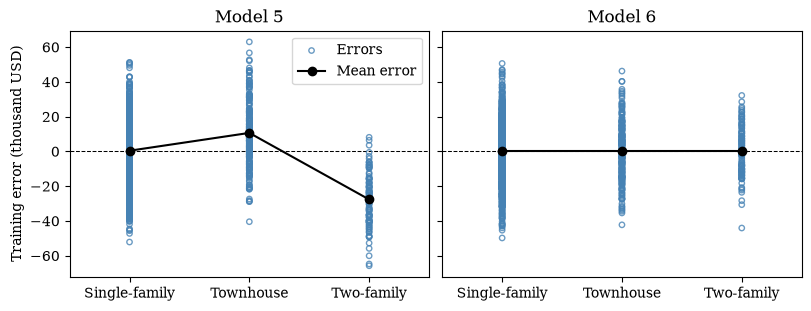

In [59]:
# Compute training errors for the plots
errors_train6 = y_train - model6.predict(X_train6)

# Compare training errors across models and building types.
errors_by_model = [errors_train5, errors_train6]
model_names = ['Model 5', 'Model 6']

plot_errors_by_building_type(errors_by_model, model_names, df_train)

We compare Model 6's test RMSE and $R^2$ with Model 5 to assess the effect of adding
the dummies. The comparison table now contains all six models:

In [60]:
# Compute test predictions for Model 6
yhat_test6 = model6.predict(X_test6)

# Compute test performance metrics for Model 6
rmse_test6 = root_mean_squared_error(y_test, yhat_test6)
r2_test6 = r2_score(y_test, yhat_test6)

# Add model 6 results to the results DataFrame
df_results.loc['Model 6'] = [rmse_test6, r2_test6]
df_results

,RMSE,R²
Model,,
Model 1,41.484218,0.644477
Model 2,27.896622,0.839230
Model 3,25.457015,0.866120
Model 4,22.387663,0.896457
Model 5,17.830097,0.934324
Model 6,15.254890,0.951925


We close this section by plotting observed versus predicted prices for Model 6.

In [61]:
def plot_predictions(ax, y, yhat, title=None):
    """
    Plot observed and predicted prices on the supplied axes.

    Parameters
    ----------
    ax : axes
        Matplotlib axes on which to draw the plot.
    y : array-like
        Observed prices in thousands of USD.
    yhat : array-like
        Predicted prices in thousands of USD.
    title : str, optional
        Title for the plot.
    """
    ax.scatter(yhat, y, s=15, c='none', ec='darkorange', alpha=0.6)
    ax.axline((0, 0), slope=1, c='black', lw=0.75, ls='--')

    xlabel = 'Predicted price (thousand USD)'
    ylabel = 'Observed price (thousand USD)'
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if title is not None:
        ax.set_title(title)

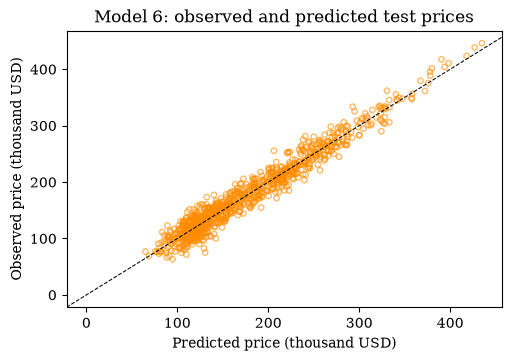

In [62]:
fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')
title = 'Model 6: observed and predicted test prices'
plot_predictions(ax, y_test, yhat_test6, title=title)

The 45-degree line represents perfect predictions. Points above it are houses
whose prices the model underpredicts; points below it are houses whose prices
the model overpredicts. This gives an overall view of Model 6's test predictions,
while the error plots show which house characteristics are associated with
systematic prediction errors.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Change `enc6` to use townhouse as the reference category and refit Model 6 on
the same data. Keep the dummies outside the polynomial and include only one
intercept. 

1. Use `np.allclose()` to compare the new test predictions with `yhat_test6`. 
2. How does the new single-family coefficient relate to the old townhouse coefficient?

</div>
<span style="display: none;">YourTurnEnd</span>

***
## List of functions used in this lecture

The following list contains the functions, classes, and methods covered in this
lecture. Official API links give details on arguments and return values; the
[[go to section]](#simple-linear-regression) links lead to their use here.
Least-squares solvers below are discussed alternatives, not executed examples.

### NumPy functions and methods

- [`default_rng()`](https://numpy.org/doc/stable/reference/random/generator.html#numpy.random.default_rng)
  Create a random number generator.
  [[go to section]](#simple-linear-regression-with-scikit-learn)
  - [`Generator.uniform()`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.uniform.html)
    Draw samples from a uniform distribution.
    [[go to section]](#simple-linear-regression-with-scikit-learn)
  - [`Generator.normal()`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html)
    Draw samples from a normal distribution.
    [[go to section]](#simple-linear-regression-with-scikit-learn)
- [`unique()`](https://numpy.org/doc/stable/reference/generated/numpy.unique.html)
  Find unique array elements.
  [[go to section]](#dealing-with-categorical-data)
- [`bincount()`](https://numpy.org/doc/stable/reference/generated/numpy.bincount.html)
  Count occurrences of nonnegative integers.
  [[go to section]](#dealing-with-categorical-data)
- [`hstack()`](https://numpy.org/doc/stable/reference/generated/numpy.hstack.html)
  Stack arrays horizontally.
  [[go to section]](#dealing-with-categorical-data)
- [`full()`](https://numpy.org/doc/stable/reference/generated/numpy.full.html)
  Create an array filled with a specified value.
  [[go to section]](#dealing-with-categorical-data)
- [`allclose()`](https://numpy.org/doc/stable/reference/generated/numpy.allclose.html)
  Check whether arrays are equal within a tolerance.
  [[go to section]](#using-scikit-learn-pipelines)
- [`lstsq()`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)
  Compute a least-squares solution to a linear system.
  [[go to section]](#simple-linear-regression)

### SciPy functions

- [`lstsq()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.lstsq.html)
  Compute a least-squares solution to a linear system.
  [[go to section]](#simple-linear-regression)

### pandas functions and methods

- [`DataFrame.corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
  Compute pairwise column correlations.
  [[go to section]](#training-and-test-samples)
- [`cut()`](https://pandas.pydata.org/docs/reference/api/pandas.cut.html)
  Bin values into discrete intervals.
  [[go to section]](#plotting-predictions-and-errors)
- [`Series.value_counts()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
  Count occurrences of unique values.
  [[go to section]](#dealing-with-categorical-data)
- [`get_dummies()`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)
  Convert categorical values into dummy variables.
  [[go to section]](#dealing-with-categorical-data)

### scikit-learn classes and functions

#### Regression models (`sklearn.linear_model`)

- [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
  Fit ordinary least squares linear regression.
  [[go to section]](#simple-linear-regression-with-scikit-learn)
  - [`fit()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression.fit)
    Fit a linear regression model.
    [[go to section]](#simple-linear-regression-with-scikit-learn)
  - [`predict()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression.predict)
    Predict response values.
    [[go to section]](#simple-linear-regression-with-scikit-learn)

#### Splitting data (`sklearn.model_selection`)

- [`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
  Split arrays into random training and test subsets.
  [[go to section]](#automatically-creating-training-and-test-samples)

#### Model evaluation (`sklearn.metrics`)

- [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html)
  Compute the mean squared prediction error.
  [[go to section]](#evaluating-the-model-fit)
- [`root_mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html)
  Compute the root mean squared prediction error.
  [[go to section]](#evaluating-the-model-fit)
- [`r2_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html)
  Compute the coefficient of determination ($R^2$).
  [[go to section]](#evaluating-the-model-fit)

#### Feature preprocessing (`sklearn.preprocessing`)

- [`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
  Generate polynomial and interaction features.
  [[go to section]](#creating-polynomial-features)
  - [`fit_transform()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html#sklearn.preprocessing.PolynomialFeatures.fit_transform)
    Fit the transformation and transform the data.
    [[go to section]](#creating-polynomial-features)
  - [`transform()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html#sklearn.preprocessing.PolynomialFeatures.transform)
    Apply the fitted transformation to data.
    [[go to section]](#creating-polynomial-features)
  - [`get_feature_names_out()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html#sklearn.preprocessing.PolynomialFeatures.get_feature_names_out)
    Return names of the transformed features.
    [[go to section]](#creating-polynomial-features)
- [`OrdinalEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html)
  Encode categorical features as integers.
  [[go to section]](#dealing-with-categorical-data)
  - [`fit_transform()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html#sklearn.preprocessing.OrdinalEncoder.fit_transform)
    Fit the transformation and transform the data.
    [[go to section]](#dealing-with-categorical-data)
- [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
  Encode categorical features as binary indicators.
  [[go to section]](#dealing-with-categorical-data)
  - [`fit_transform()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html#sklearn.preprocessing.OneHotEncoder.fit_transform)
    Fit the transformation and transform the data.
    [[go to section]](#dealing-with-categorical-data)
  - [`transform()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html#sklearn.preprocessing.OneHotEncoder.transform)
    Apply the fitted transformation to data.
    [[go to section]](#dealing-with-categorical-data)
  - [`get_feature_names_out()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html#sklearn.preprocessing.OneHotEncoder.get_feature_names_out)
    Return names of the transformed features.
    [[go to section]](#dealing-with-categorical-data)

#### Pipelines (`sklearn.pipeline`)

- [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
  Chain transformers and a final estimator.
  [[go to section]](#using-scikit-learn-pipelines)
  - [`fit()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline.fit)
    Fit the transformers and final estimator.
    [[go to section]](#using-scikit-learn-pipelines)
  - [`predict()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline.predict)
    Transform data and predict response values.
    [[go to section]](#using-scikit-learn-pipelines)
- [`make_pipeline()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html)
  Build a pipeline with automatically assigned step names.
  [[go to section]](#using-scikit-learn-pipelines)

### statsmodels classes and methods

- [`OLS`](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html)
  Specify an ordinary least squares regression model.
  [[go to section]](#digression-machine-learning-versus-econometrics)
  - [`fit()`](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.fit.html)
    Fit the model and return regression results.
    [[go to section]](#digression-machine-learning-versus-econometrics)
- [`add_constant()`](https://www.statsmodels.org/stable/generated/statsmodels.tools.tools.add_constant.html)
  Add a column of ones to an array.
  [[go to section]](#digression-machine-learning-versus-econometrics)
- [`summary()`](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.summary.html)
  Summarize regression results.
  [[go to section]](#digression-machine-learning-versus-econometrics)
- [`conf_int()`](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.conf_int.html)
  Compute confidence intervals for model parameters.
  [[go to section]](#digression-machine-learning-versus-econometrics)